# Edge Pilot: constraint-aware model selection and monitoring

**Question:** Can a bounded engineering workflow choose a model that satisfies deployment constraints, and report infeasibility honestly?

A planner proposes candidates, a runner measures validation performance and resource usage, and a critic enforces hard gates. The workflow handles saved candidates and on-demand training. [Project guide](../projects/03-edge-pilot/README.md)

## Reading roadmap

Inspect the objective and four gates, review each candidate, verify the no-feasible-candidate case, and then examine held-out reporting and monitoring. The later pruning gate is a separate size/quality example. Keep the distinction between choosing with validation data and reporting with test data in mind throughout.

Read the explanations before executing each block, and run cells in order: later blocks reuse variables created earlier. Saved output is a record of an earlier execution; running a report cell reads the report files currently in your checkout.


## How to run
Run all cells from the repository root or this directory. Install the notebook extra with `uv pip install -e '.[notebooks]'` and select that Python environment. The report sections need only committed JSON measurements. They do not need checkpoints, API keys, downloads, or Apple hardware. Edge Sense and Edge Pilot also have an optional local inference section that needs generated checkpoints and validation arrays. Saved study outputs and fresh local measurements are labeled separately.

## What decision this program makes

A model with the highest accuracy may be too large or too slow for the target device. A very small model may fit but fail when the gyroscope stops working. Edge Pilot compares candidates against all of these requirements at once.

The inputs are candidate checkpoints and a JSON objective. The output is a selected candidate plus the measurements and checks that led to the choice. If every candidate violates a requirement, the correct output is “no feasible candidate.” It does not quietly relax the requirements to produce a winner.

## Planner, runner, and critic in code

The **planner** chooses what to evaluate next. The **runner** loads or trains that candidate and measures it. The **critic** compares the measurements with the objective. These are separate pieces of program logic, which makes their decisions easier to inspect.

The saved-candidate path evaluates existing model files. The training-search path proposes small network widths and trains new candidates. Its width setting controls how many channels the convolutional layers use. A lower width usually means fewer weights, but its accuracy must still be measured. The search is bounded by a trial count and a time budget; it is not an open-ended optimizer.

## The four gates

A candidate must pass a minimum validation macro F1, a minimum validation F1 under gyro outage, a maximum CPU p95 duration, and a maximum serialized file size. Passing three out of four is a failure.

The plot shows only file size and clean validation F1 so it stays readable. The table and the check function include outage robustness and timing too. The saved-candidate and training searches have different objectives, so their winners are not competing under identical rules. The checks below recompute feasibility from the saved measurements rather than trusting the saved boolean alone.

## Why the selected model still needs a test report

Choosing a model based on validation results can favor a candidate that happened to do well on those subjects. The separate test report shows what happened on people the selection process did not use.

The on-demand search has one training seed per candidate. Small differences in test scores should not be treated as a stable ranking. The selected model stays the one chosen by the validation objective; looking at the test table does not trigger another round of selection.

## What the monitoring replay is showing

The replay sends validation windows through the chosen model in short groups. Halfway through, it replaces the gyroscope channels with a synthetic outage. The red region marks where that fault was injected.

Gyroscope variance drops because those channels no longer change. Prediction quality can drop too. A monitoring rule uses the signal change to raise an alert. The replay has labels, so it can also show macro F1 after the fact. A real application usually does not receive immediate ground-truth activity labels, which makes online quality monitoring harder. This example is a controlled failure demonstration, not a production service.

**Before you run:** Run this setup first so later cells can locate the repository, read the saved reports, and display consistent tables and plots.

**How to read the output:** This loads recorded measurements into memory; it does not train a model or rerun the original experiments. A printed SHA256 identifies the exact report bytes used.


In [1]:
from pathlib import Path
import hashlib
import json
import statistics
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports/results.json").is_file())
RESULTS_PATH = ROOT / "reports/results.json"
r = json.loads(RESULTS_PATH.read_text())
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
def table(headers, rows):
    def cell(v):
        return str(v).replace("|", " / ").replace("\n", " ")
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" + "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)))
print("Evidence:", RESULTS_PATH.relative_to(ROOT))
print("SHA256:", hashlib.sha256(RESULTS_PATH.read_bytes()).hexdigest())
print("This notebook reanalyzes saved measurements; it does not rerun training or download data.")

Evidence: reports/results.json
SHA256: b382e4a91a7e8103fa6ab03709309848592cd80b8a4ee3c777e6e82ce588636d
This notebook reanalyzes saved measurements; it does not rerun training or download data.


## Selection boundary
Validation accuracy, validation gyro-outage robustness, CPU p95 latency, and serialized state determine feasibility. Test results are reporting only. The planner–runner–critic is a bounded software workflow; it does not imply an autonomous language-model optimizer. Different searches have different storage gates.

**Before you run:** First verify the decision rule. The saved-candidate pilot and on-demand search have separate objectives; this cell recomputes all four feasibility checks from saved validation and benchmark measurements.

**How to read the output:** A candidate passes only when quality and outage quality meet their floors and latency and storage stay within their ceilings. Successful assertions show consistency with the saved measurements, not a fresh benchmark or a new search run.


In [2]:
for key in ("pilot", "search"):
    s = r[key]
    assert s["selection_split"] == "validation" and s["test_metrics_used"] is False
    print(key, "objective:", s["objective"])
    print("Winner:", s["winner"]["candidate"], "| trials:", s["trials"])

def feasible(c, objective):
    return (c["validation"]["macro_f1"] >= objective["min_macro_f1"]
            and c["dropout_macro_f1"] >= objective["min_dropout_f1"]
            and c["benchmark"]["p95_ms"] <= objective["max_p95_ms"]
            and c["benchmark"]["state_dict_bytes"] <= objective["max_bytes"])
for key in ("pilot", "search"):
    s = r[key]
    assert all(feasible(c, s["objective"]) == c["feasible"] for c in s["candidates"])
    assert feasible(s["winner"], s["objective"])
print("All saved feasibility decisions independently recomputed.")

pilot objective: {'min_macro_f1': 0.85, 'max_p95_ms': 2.0, 'max_bytes': 150000, 'min_dropout_f1': 0.45, 'max_trials': 8, 'max_seconds': 600.0}
Winner: dynamic_int8 | trials: 8
search objective: {'min_macro_f1': 0.9, 'max_p95_ms': 2.0, 'max_bytes': 32000, 'min_dropout_f1': 0.75, 'max_trials': 3, 'max_seconds': 900.0}
Winner: width-6-base | trials: 3
All saved feasibility decisions independently recomputed.


**Before you run:** Inspect why candidates pass or fail before accepting the winner. The table exposes all four measured gates; the plot shows only storage and ordinary validation quality.

**How to read the output:** Green means all four gates pass. A point can sit on the acceptable side of both plotted lines and still fail outage robustness or latency. Smaller and higher is attractive on this plot, but the complete decision requires the table.


| Trained candidate | Val F1 | Val outage F1 | KiB | CPU p95 ms | Feasible |
| --- | --- | --- | --- | --- | --- |
| width-6-robust | 0.9589 | 0.9211 | 20.9 | 0.087 | True |
| width-6-base | 0.9576 | 0.9320 | 20.9 | 0.087 | True |
| width-4-robust | 0.9577 | 0.8994 | 13.5 | 0.060 | True |

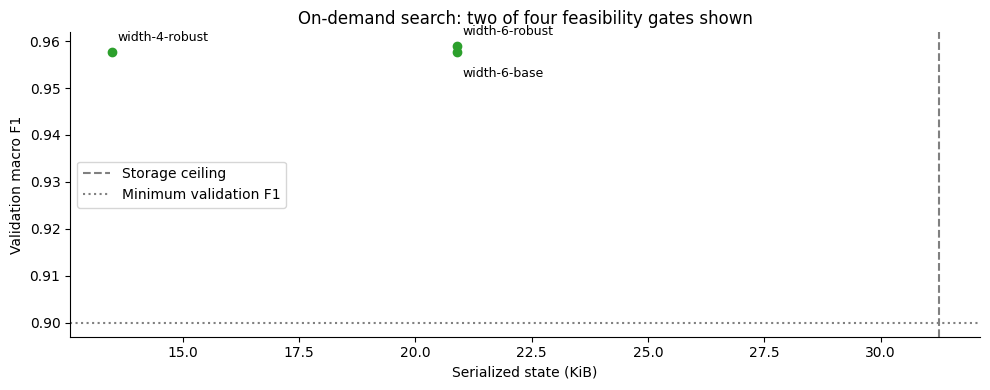

In [3]:
s = r["search"]
table(["Trained candidate", "Val F1", "Val outage F1", "KiB", "CPU p95 ms", "Feasible"], [(c["candidate"], f'{c["validation"]["macro_f1"]:.4f}', f'{c["dropout_macro_f1"]:.4f}', f'{c["benchmark"]["state_dict_bytes"]/1024:.1f}', f'{c["benchmark"]["p95_ms"]:.3f}', c["feasible"]) for c in s["candidates"]])
fig, ax = plt.subplots()
for c in s["candidates"]:
    x, y = c["benchmark"]["state_dict_bytes"]/1024, c["validation"]["macro_f1"]
    ax.scatter(x, y, color="tab:green" if c["feasible"] else "tab:red")
    ax.annotate(c["candidate"], (x, y), xytext=(4, -18 if c["candidate"] == "width-6-base" else 8), textcoords="offset points", fontsize=9)
ax.axvline(s["objective"]["max_bytes"]/1024, linestyle="--", color="gray", label="Storage ceiling")
ax.axhline(s["objective"]["min_macro_f1"], linestyle=":", color="gray", label="Minimum validation F1")
ax.set(xlabel="Serialized state (KiB)", ylabel="Validation macro F1", title="On-demand search: two of four feasibility gates shown")
ax.legend(); plt.tight_layout(); plt.show()

## Infeasibility and held-out reporting
A separate 1,024-byte gate intentionally makes the candidate set infeasible. The system must return no winner instead of promoting a fallback. Held-out scores below are inspected only after validation selection.

**Before you run:** Check two different outcomes: a deliberately impossible storage budget and the held-out report for a model selected under the ordinary rule.

**How to read the output:** No feasible candidate is a valid result when every option violates the budget. The held-out score describes the selected model after selection; it must not be used to relax gates or choose another candidate.


In [4]:
probe = r["infeasible_pilot"]
assert probe["status"] == "no_feasible_candidate" and probe["winner"] is None
assert r["search_test"]["used_for_selection"] is False
print("Infeasible probe:", probe["status"], "| storage gate:", probe["objective"]["max_bytes"], "bytes")
table(["Candidate", "Test F1", "Test gyro-outage F1"], [(c["candidate"], f'{c["clean"]["macro_f1"]:.4f}', f'{c["stress"]["gyro_dropout"]["macro_f1"]:.4f}') for c in r["search_test"]["results"]])

Infeasible probe: no_feasible_candidate | storage gate: 1024 bytes


| Candidate | Test F1 | Test gyro-outage F1 |
| --- | --- | --- |
| trained/width-4-robust | 0.9065 | 0.8370 |
| trained/width-6-base | 0.9059 | 0.8337 |
| trained/width-6-robust | 0.9046 | 0.8312 |

## Shadow monitoring
The replay shuffles labeled validation windows and introduces a synthetic gyroscope outage halfway. Labels enable retrospective F1 measurement; this is not live production telemetry or evidence that deployment occurred.

**Before you run:** Read the replay as a controlled fault experiment on real validation recordings. The sensor outage is injected, and red shading identifies the affected replay groups.

**How to read the output:** Compare gyroscope variance with retrospective macro F1 to see whether the sensor signal and prediction quality change together. Replay-window indices represent groups in this experiment, not a live production timeline. Detection and false-alert counts describe this replay only.


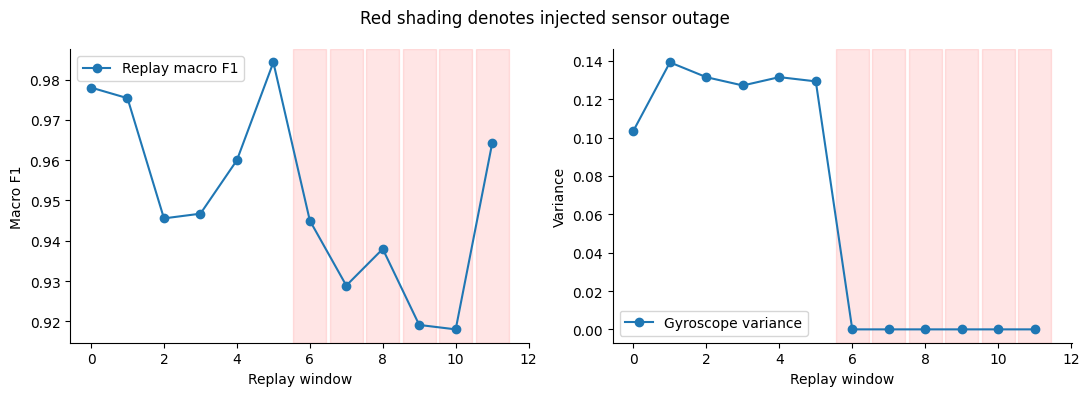

Recorded source: shuffled labeled validation replay with synthetic gyro outage halfway
False alerts: 0 | outage detection rate: 1.0


In [5]:
events = r["telemetry"]["events"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot([e["window"] for e in events], [e["macro_f1"] for e in events], marker="o", label="Replay macro F1")
axes[1].plot([e["window"] for e in events], [e["gyro_variance"] for e in events], marker="o", label="Gyroscope variance")
for ax in axes:
    for e in events:
        if e["synthetic_outage"]:
            ax.axvspan(e["window"]-.45, e["window"]+.45, alpha=.1, color="red")
    ax.set_xlabel("Replay window"); ax.legend()
axes[0].set_ylabel("Macro F1"); axes[1].set_ylabel("Variance")
fig.suptitle("Red shading denotes injected sensor outage")
plt.tight_layout(); plt.show()
print("Recorded source:", r["telemetry"]["source"])
print("False alerts:", r["telemetry"]["false_alerts"], "| outage detection rate:", r["telemetry"]["outage_detection_rate"])

## Interpretation and reproduction
The search selects width-6-base under its 32,000-byte state budget; the saved-candidate pilot selects dynamic INT8 under a different budget. This is a small candidate search, with single-seed evidence for newly trained candidates. CPU latency is host-specific; serialized state excludes runtime memory. A wall-time budget is checked between indivisible jobs, so a job can overrun the remaining time. No production promotion occurred.

Run `edge-lab pilot --objective configs/pilot.json` for saved candidates or `python scripts/run_search.py` for training search options. Full commands and prerequisites are in [reproduction instructions](../docs/REPRODUCING.md).

## Try inference on this machine

This optional section loads a **floating-point** checkpoint and real validation windows. `auto` selects CUDA when available, then Apple MPS, then CPU. Set `DEVICE = "cuda"`, `"mps"`, or `"cpu"` to request one explicitly. An unavailable explicit choice raises an error rather than silently reporting CPU work as GPU work.

Checkpoints and sensor arrays are not stored in Git. If they are missing, the cell prints the commands needed to generate them and skips the benchmark. It does not download data or train anything on its own. The plots above still work without these files.

The benchmark keeps a batch on the device, warms up the network, then waits for device work to finish around each timed call. Input transfers and loading are outside the timer. The result is **batch forward duration**, not end-to-end application latency. Use batch size 1 to measure single-window calls, or 64 to explore throughput. A GPU can be slower for a network this small.

The returned probabilities are compared against the same floating model on CPU. Small numerical differences are expected. This does not compare a floating GPU model against the CPU-only dynamic INT8 implementation.

Timing details: [CUDA synchronization](https://docs.pytorch.org/docs/stable/generated/torch.cuda.synchronize.html) and [MPS synchronization](https://docs.pytorch.org/docs/stable/generated/torch.mps.synchronize.html).

**Before you run:** This is a fresh local experiment. Run the setup above first, install the project and PyTorch, and generate the checkpoint and validation arrays using the commands in this section. Choose DEVICE and BATCH_SIZE before execution; auto prefers CUDA, then MPS, then CPU.

**How to read the output:** The cell compares predictions on the first 256 validation windows with a CPU reference. Higher top-1 agreement and smaller probability differences indicate closer numerical parity. Batch p95 is a batch duration, not a per-window latency. Missing local artifacts produce a skip message; these timings describe your current machine.


In [6]:
import torch
from edge_agent_lab.inference import resolve_device, run_inference
from edge_agent_lab.models import load_model
from edge_agent_lab.data import ensure_data, load_split
import numpy as np

DEVICE = "auto"  # Or explicitly request "cuda", "mps", or "cpu".
BATCH_SIZE = 64   # Set to 1 for single-window timing.
CHECKPOINT = ROOT / "artifacts/search/trained/width-6-base/model.pt"
DATA_ROOT = ROOT / "data/har"
print("Available:", {"cuda": torch.cuda.is_available(), "mps": torch.backends.mps.is_available()})
print("Selected device:", resolve_device(DEVICE))
if not CHECKPOINT.is_file() or not (DATA_ROOT / "val.npz").is_file():
    print("Skipped: this checkout has no local checkpoint or validation arrays.")
    print("From the repository root: edge-lab prepare")
    print("Then: edge-lab train --seeds 7 --epochs 40 --compact")
    print("For the search checkpoint also run: python scripts/run_search.py")
else:
    ensure_data(DATA_ROOT)  # Check cached file hashes before loading.
    model = load_model(CHECKPOINT)
    windows = load_split(DATA_ROOT, "val").x[:256]
    # This fixed subset checks execution and parity, not validation-wide accuracy.
    current, timing = run_inference(model, windows, DEVICE, BATCH_SIZE, repeats=20)
    reference, cpu_timing = run_inference(model, windows, "cpu", BATCH_SIZE, repeats=20)
    table(["Measurement", "Selected device", "CPU reference"], [
        ("Device", timing["device"], cpu_timing["device"]),
        ("Batch size", timing["batch_size"], cpu_timing["batch_size"]),
        ("Batch p50 ms", round(timing["batch_p50_ms"], 3), round(cpu_timing["batch_p50_ms"], 3)),
        ("Batch p95 ms", round(timing["batch_p95_ms"], 3), round(cpu_timing["batch_p95_ms"], 3)),
        ("Windows/sec at p50", round(timing["windows_per_second_at_p50"]), round(cpu_timing["windows_per_second_at_p50"])),
    ])
    agreement = float((current.argmax(1) == reference.argmax(1)).mean())
    print("Top-1 agreement with CPU:", agreement)
    print("Maximum probability difference:", float(np.abs(current-reference).max()))
    print("Hardware:", timing["hardware"], "| PyTorch:", timing["torch"])
    print("Timing scope:", timing["timing_scope"])
    print("These are fresh local measurements, separate from the saved study.")

Available: {'cuda': False, 'mps': True}
Selected device: mps


| Measurement | Selected device | CPU reference |
| --- | --- | --- |
| Device | mps | cpu |
| Batch size | 64 | 64 |
| Batch p50 ms | 1.135 | 2.078 |
| Batch p95 ms | 1.395 | 2.551 |
| Windows/sec at p50 | 56397 | 30805 |

Top-1 agreement with CPU: 1.0
Maximum probability difference: 9.238719940185547e-07
Hardware: Apple GPU (MPS) | PyTorch: 2.2.2
Timing scope: resident-input forward; includes dispatch and synchronization; no transfers
These are fresh local measurements, separate from the saved study.


To evaluate all validation windows and save the result outside the notebook:

```bash
edge-infer --checkpoint artifacts/search/trained/width-6-base/model.pt --device auto --batch-size 64
```

Use `--device cuda` on an NVIDIA machine with a compatible CUDA-enabled PyTorch installation. The default dependency pin is PyTorch 2.2.2, which may not support newer GPU architectures; a different CUDA/PyTorch environment needs its own compatibility checks and should be recorded as a separate environment. Do not replace the pinned study dependencies just to view the saved results.

The command saves fresh results to `artifacts/inference/latest.json`. It does not overwrite `reports/results.json`, retrain the model, or change which candidate was selected.

## Pruning an already trained network

The earlier comparisons use distillation and quantization. **Distillation** changes how a smaller network learns from a teacher. **Quantization** stores or computes selected weights using fewer bits. **Pruning** removes connections or channels from a network that already has trained weights. These methods solve related problems, but they are different operations.

The added experiment starts from the same seed-7 floating distilled student for every candidate. It compares the original model, a dense model with extra fine-tuning, two magnitude-pruned models, and two physically smaller channel-pruned models. The extra dense run is a control: otherwise an apparent pruning benefit could simply come from giving a model more training.

Results below come from `reports/pruning.json`, separate from the original three-seed study. This added comparison uses one checkpoint and one fine-tuning seed.

**Before you run:** Load the pruning report before comparing candidates. All candidates should trace back to the recorded source checkpoint, so differences have a common starting point.

**How to read the output:** The checkpoint fingerprint and selection rule describe experiment provenance. The assertion checks the saved claim that test data was excluded from selection; it does not rerun training.


In [7]:
pruning = json.loads((ROOT / "reports/pruning.json").read_text())
pruned = {c["name"]: c for c in pruning["candidates"]}
print("Source checkpoint SHA256:", pruning["source_sha256"])
print("Fine-tuning seed:", pruning["seed"], "| maximum epochs:", pruning["fine_tuning_epochs"])
print("Selection:", pruning["selection_rule"])
assert pruning["test_used_for_selection"] is False

Source checkpoint SHA256: d207e077aa5751f87c518590e3afdc8e680bd71220900ee687217bbe61c1f0ab
Fine-tuning seed: 7 | maximum epochs: 5
Selection: smallest state within 0.02 validation macro F1 of original dense source


### Apply a size/quality gate to the pruning candidates

This is a separate selection example, not a replacement for the original Edge Pilot run. Its rule is fixed: keep candidates whose validation macro F1 is no more than 0.02 below the unpruned source, then choose the smallest checkpoint. A 0.02 difference is two percentage points on this score. The rule does not inspect test scores or use timing to choose a winner.

The original dense model remains a candidate, so there is a valid fallback when every compact model loses too much validation quality. This example has a quality floor rather than the four deployment gates in the earlier pilot. A real target could add a measured latency or memory ceiling.

**Before you run:** Apply the separate pruning rule to saved candidates: filter by the validation quality floor, then select the smallest passing checkpoint.

**How to read the output:** The table makes rejection visible before the selected model is reported. This example uses quality and size only; it does not repeat the original four-gate search. Test quality remains a reporting result and cannot rescue or reject a candidate during selection.


In [8]:
floor = pruning["minimum_validation_f1"]
passing = [c for c in pruning["candidates"] if c["validation"]["macro_f1"] >= floor]
selected = min(passing, key=lambda c: (c["checkpoint_bytes"], -c["validation"]["macro_f1"]))
assert selected["name"] == pruning["selected"]
table(["Candidate", "Validation F1", "Passes quality floor", "Checkpoint KiB"], [
    (c["name"], f'{c["validation"]["macro_f1"]:.4f}', c["validation"]["macro_f1"] >= floor, f'{c["checkpoint_bytes"]/1024:.1f}')
    for c in pruning["candidates"]])
print(f"Validation floor: {floor:.4f}; selected: {selected['name']}")
print(f"Selected model test F1 (reporting only): {selected['test']['macro_f1']:.4f}")

| Candidate | Validation F1 | Passes quality floor | Checkpoint KiB |
| --- | --- | --- | --- |
| dense_original | 0.9602 | True | 59.6 |
| dense_finetuned | 0.9602 | True | 59.6 |
| magnitude_50 | 0.9553 | True | 59.6 |
| magnitude_70 | 0.9531 | True | 59.6 |
| channels_75pct | 0.9672 | True | 37.7 |
| channels_50pct | 0.9450 | True | 20.8 |

Validation floor: 0.9402; selected: channels_50pct
Selected model test F1 (reporting only): 0.8969


The half-width model passes this validation rule, but its test score is lower than the source. That is a useful example of why “passes the selection gate” and “no accuracy cost” are different statements. The selected checkpoint can be passed to `edge-infer` for CPU/CUDA/MPS measurement. It has not been inserted into the old pilot artifacts or promoted to production. [Pruning details](../docs/PRUNING.md).

## Pruning and quantization toolkit

The [dedicated optimization notebook](04_post_training_toolkit.ipynb) collects magnitude pruning, physical channel removal, dynamic INT8, calibrated static INT8 for both convolution and linear layers, QAT, and pruning + quantization. It includes runnable examples, export/load checks, measured size and timing comparisons, and CPU/GPU runtime limits. QAT and pruning recovery are labeled fine-tuning steps; PTQ itself does not train weights.